<a href="https://colab.research.google.com/github/samnocera05-ui/mis433/blob/main/churn_prediction.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Competition - Customer Churn Prediction

MIS 433 - Fall 2026

Customer churn is the loss of clients or customers. In this notebook, I conduct a churn analysis on a data set of a telecommunication company and build classification models to predict customer churn.

Outline:
1. Read the data files
2. Describe/summarize the data sets
3. Data integration
4. Exploratory data analysis
5. Preprocessing
6. Building the models
7. Making predictions for submission on Kaggle

In [67]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
%matplotlib inline

In [68]:
# Colab only: mount Google Drive and set the data folder and the output folder for submissions
from google.colab import drive

drive.mount('/content/drive')

data_dir = '/content/drive/My Drive/Colab Notebooks/Assignments/MIS 433 - Churn Competition/data/'
output_dir = '/content/drive/My Drive/Colab Notebooks/Assignments/MIS 433 - Churn Competition/output/'
os.makedirs(output_dir, exist_ok=True)
print(f'Submission files will be saved to: {output_dir}')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Submission files will be saved to: /content/drive/My Drive/Colab Notebooks/Assignments/MIS 433 - Churn Competition/output/


## 1. Read the Data Files

The competition provides six files:
- `churn_train.csv` - the training set (CustomerNo and Churn)
- `churn_test.csv` - the test set (CustomerNo only)
- `accounts.csv` - account information of all customers
- `demographics.csv` - demographics of all customers
- `services.csv` - services opted for by all customers
- `sample_submission.csv` - a sample submission file in the correct format

In [69]:
# Load the training set
df_train = pd.read_csv(f'{data_dir}churn_train.csv')
df_train.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 4238 entries, 0 to 4237
Data columns (total 2 columns):
 #   Column      Non-Null Count  Dtype
---  ------      --------------  -----
 0   CustomerNo  4238 non-null   int64
 1   Churn       4238 non-null   int64
dtypes: int64(2)
memory usage: 66.3 KB


In [70]:
# Load the test set
df_test = pd.read_csv(f'{data_dir}churn_test.csv')
df_test.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1060 entries, 0 to 1059
Data columns (total 1 columns):
 #   Column      Non-Null Count  Dtype
---  ------      --------------  -----
 0   CustomerNo  1060 non-null   int64
dtypes: int64(1)
memory usage: 8.4 KB


In [71]:
# Load the three tables that describe the customers
df_accounts = pd.read_csv(f'{data_dir}accounts.csv')
df_demographics = pd.read_csv(f'{data_dir}demographics.csv')
df_services = pd.read_csv(f'{data_dir}services.csv')
df_sample = pd.read_csv(f'{data_dir}sample_submission.csv')

## 2. Describe/Summarize the Data Sets

In [72]:
# rows and columns of each data set
for name, d in [('churn_train', df_train), ('churn_test', df_test), ('accounts', df_accounts),
                ('demographics', df_demographics), ('services', df_services), ('sample_submission', df_sample)]:
    print(f'{name}: {d.shape[0]} rows, {d.shape[1]} columns')

churn_train: 4238 rows, 2 columns
churn_test: 1060 rows, 1 columns
accounts: 5298 rows, 8 columns
demographics: 5298 rows, 8 columns
services: 47682 rows, 3 columns
sample_submission: 1060 rows, 2 columns


### Training set

In [73]:
df_train.head()

,CustomerNo,Churn
0,1201,0
1,1202,0
2,1205,1
3,1206,0
4,1207,0


In [74]:
# 'Churn' is the target
s = df_train['Churn'].value_counts()
print(s)
print(f'the churn rate is {s[1]/s.sum():.1%}')

Churn
0    3189
1    1049
Name: count, dtype: int64
the churn rate is 24.8%


About one out of four customers in the training set churned. A naive model that predicts Churn = 0 for all would be right about 75% of the time on the training set, so accuracy needs to be read against that number.

### Accounts

In [75]:
df_accounts.head()

,CustomerNo,BaseCharges,DOC,TotalCharges,DOE,ElectronicBilling,ContractType,PaymentMethod
0,1201,478.50,5-1-2012,5920.00,10-Jan-11,No,One year,Electronic check
1,1202,103.25,5-1-2012,103.25,6-Dec-11,No,Month-to-month,Electronic check
2,1203,399.75,5-1-2012,5217.00,10-Jan-11,Yes,Month-to-month,Bank transfer (automatic)
3,1204,324.75,5-1-2012,22757.50,6-Apr-06,No,One year,Bank transfer (automatic)
4,1205,372.50,5-1-2012,372.50,6-Dec-11,Yes,Month-to-month,Electronic check


In [76]:
df_accounts.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 5298 entries, 0 to 5297
Data columns (total 8 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   CustomerNo         5298 non-null   int64  
 1   BaseCharges        5298 non-null   float64
 2   DOC                5298 non-null   object 
 3   TotalCharges       5288 non-null   float64
 4   DOE                5298 non-null   object 
 5   ElectronicBilling  5298 non-null   object 
 6   ContractType       5293 non-null   object 
 7   PaymentMethod      5298 non-null   object 
dtypes: float64(2), int64(1), object(5)
memory usage: 331.3+ KB


In [77]:
df_accounts.describe(include='all')

,CustomerNo,BaseCharges,DOC,TotalCharges,DOE,ElectronicBilling,ContractType,PaymentMethod
count,5298.000000,5298.000000,5298,5288.000000,5298,5298,5293,5298
unique,NaN,NaN,1,NaN,73,2,3,4
top,NaN,NaN,5-1-2012,NaN,6-Dec-11,Yes,Month-to-month,Electronic check
freq,NaN,NaN,5298,NaN,423,3120,2779,1586
mean,3849.500000,325.467205,NaN,11928.354056,NaN,NaN,NaN,NaN
std,1529.545194,151.352954,NaN,11486.453199,NaN,NaN,NaN,NaN
min,1201.000000,91.250000,NaN,94.250000,NaN,NaN,NaN,NaN
25%,2525.250000,178.250000,NaN,2314.937500,NaN,NaN,NaN,NaN
50%,3849.500000,352.500000,NaN,7377.500000,NaN,NaN,NaN,NaN
75%,5173.750000,451.250000,NaN,19992.812500,NaN,NaN,NaN,NaN


In [78]:
# total null values
df_accounts.isnull().sum()

,0
CustomerNo,0
BaseCharges,0
DOC,0
TotalCharges,10
DOE,0
ElectronicBilling,0
ContractType,5
PaymentMethod,0


- `DOC` has only one value (5-1-2012) for every customer. It looks like the date the data was collected.
- `DOE` looks like the date the customer joined.
- `TotalCharges` has 10 missing values and `ContractType` has 5.

### Demographics

In [79]:
df_demographics.head()

,CustomerNo,Country,State,Retired,HasPartner,HasDependents,Education,Gender
0,1201,India,Maharashtra,0,2,2,Masters,Male
1,1202,India,Maharashtra,0,2,2,ProfessionalQalification,Male
2,1203,India,Maharashtra,0,2,2,ProfessionalQalification,Male
3,1204,India,Maharashtra,0,2,1,ProfessionalQalification,Male
4,1205,India,Maharashtra,0,2,2,ProfessionalQalification,Female


In [80]:
df_demographics.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 5298 entries, 0 to 5297
Data columns (total 8 columns):
 #   Column         Non-Null Count  Dtype 
---  ------         --------------  ----- 
 0   CustomerNo     5298 non-null   int64 
 1   Country        5298 non-null   object
 2   State          5298 non-null   object
 3   Retired        5298 non-null   int64 
 4   HasPartner     5298 non-null   int64 
 5   HasDependents  5298 non-null   int64 
 6   Education      5288 non-null   object
 7   Gender         5294 non-null   object
dtypes: int64(4), object(4)
memory usage: 331.3+ KB


In [81]:
df_demographics.describe(include='all')

,CustomerNo,Country,State,Retired,HasPartner,HasDependents,Education,Gender
count,5298.000000,5298,5298,5298.000000,5298.000000,5298.000000,5288,5294
unique,NaN,2,2,NaN,NaN,NaN,5,2
top,NaN,India,Maharashtra,NaN,NaN,NaN,Highschool or below,Male
freq,NaN,5293,5290,NaN,NaN,NaN,1426,2656
mean,3849.500000,NaN,NaN,0.158362,1.502454,1.690827,NaN,NaN
std,1529.545194,NaN,NaN,0.365114,0.500041,0.462196,NaN,NaN
min,1201.000000,NaN,NaN,0.000000,1.000000,1.000000,NaN,NaN
25%,2525.250000,NaN,NaN,0.000000,1.000000,1.000000,NaN,NaN
50%,3849.500000,NaN,NaN,0.000000,2.000000,2.000000,NaN,NaN
75%,5173.750000,NaN,NaN,0.000000,2.000000,2.000000,NaN,NaN


In [82]:
df_demographics.isnull().sum()

,0
CustomerNo,0
Country,0
State,0
Retired,0
HasPartner,0
HasDependents,0
Education,10
Gender,4


In [83]:
# value counts of each demographic variable
for col in ['Country', 'State', 'Retired', 'HasPartner', 'HasDependents', 'Education', 'Gender']:
    print(df_demographics[col].value_counts(dropna=False))
    print()

Country
India    5293
?           5
Name: count, dtype: int64

State
Maharashtra    5290
?                 8
Name: count, dtype: int64

Retired
0    4459
1     839
Name: count, dtype: int64

HasPartner
2    2662
1    2636
Name: count, dtype: int64

HasDependents
2    3660
1    1638
Name: count, dtype: int64

Education
Highschool or below         1426
Graduation                  1370
Masters                     1265
ProfessionalQalification    1186
Other                         41
NaN                           10
Name: count, dtype: int64

Gender
Male      2656
Female    2638
NaN          4
Name: count, dtype: int64



- `Country` and `State` are almost constant (India / Maharashtra, with a few '?'), so they are not useful for predicting.
- `HasPartner` and `HasDependents` are coded as 1 and 2.
- `Education` has 10 missing values and `Gender` has 4.

### Services

In [84]:
df_services.head(10)

,CustomerNo,TypeOfService,SeviceDetails
0,1201,DeviceProtection,Yes
1,1201,HasPhoneService,1
2,1201,InternetServiceCategory,Fiber optic
3,1201,MultipleLines,No
4,1201,OnlineBackup,No
5,1201,OnlineSecurity,No
6,1201,StreamingMovies,Yes
7,1201,StreamingTelevision,Yes
8,1201,TechnicalSupport,No
9,1202,DeviceProtection,No internet service


In [85]:
df_services.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 47682 entries, 0 to 47681
Data columns (total 3 columns):
 #   Column         Non-Null Count  Dtype 
---  ------         --------------  ----- 
 0   CustomerNo     47682 non-null  int64 
 1   TypeOfService  47682 non-null  object
 2   SeviceDetails  47682 non-null  object
dtypes: int64(1), object(2)
memory usage: 1.1+ MB


In [86]:
# each customer has 9 rows, one for each type of service
df_services.groupby('TypeOfService')['SeviceDetails'].value_counts()

TypeOfService            SeviceDetails      
DeviceProtection         No                     2253
                         Yes                    1889
                         No internet service    1156
HasPhoneService          1                      4792
                         0                       506
InternetServiceCategory  Fiber optic            2313
                         DSL                    1829
                         No                     1156
MultipleLines            No                     2491
                         Yes                    2301
                         No phone service        506
OnlineBackup             No                     2270
                         Yes                    1872
                         No internet service    1156
OnlineSecurity           No                     2569
                         Yes                    1573
                         No internet service    1156
StreamingMovies          Yes                    2075
                         No                     2067
                         No internet service    1156
StreamingTelevision      Yes                    2075
                         No                     2067
                         No internet service    1156
TechnicalSupport         No                     2537
                         Yes                    1605
                         No internet service    1156
Name: count, dtype: int64

The services table is not tidy: each customer has 9 rows, and the variable names are stored in the `TypeOfService` column. It needs to be pivoted to a wide table (one row per customer) before it can be merged with the other tables.

## 3. Data Integration

### Tidy the services table

In [87]:
# pivot the services table from long to wide: one row per customer, one column per type of service
df_services_wide = (
    df_services
    .pivot(index='CustomerNo', columns='TypeOfService', values='SeviceDetails')
    .reset_index()
)
df_services_wide.columns.name = None
df_services_wide.head()

,CustomerNo,DeviceProtection,HasPhoneService,InternetServiceCategory,MultipleLines,OnlineBackup,OnlineSecurity,StreamingMovies,StreamingTelevision,TechnicalSupport
0,1201,Yes,1,Fiber optic,No,No,No,Yes,Yes,No
1,1202,No internet service,1,No,No,No internet service,No internet service,No internet service,No internet service,No internet service
2,1203,No,1,Fiber optic,No,No,No,Yes,No,No
3,1204,No,1,DSL,Yes,Yes,Yes,No,No,Yes
4,1205,No,1,Fiber optic,Yes,No,No,No,No,No


In [88]:
df_services_wide.shape

(5298, 10)

### Merge the tables

In [89]:
# combine accounts, demographics, and services into one customer table using CustomerNo as the key
df_customers = pd.merge(df_accounts, df_demographics, how='left', on='CustomerNo')
df_customers = pd.merge(df_customers, df_services_wide, how='left', on='CustomerNo')
df_customers.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 5298 entries, 0 to 5297
Data columns (total 24 columns):
 #   Column                   Non-Null Count  Dtype  
---  ------                   --------------  -----  
 0   CustomerNo               5298 non-null   int64  
 1   BaseCharges              5298 non-null   float64
 2   DOC                      5298 non-null   object 
 3   TotalCharges             5288 non-null   float64
 4   DOE                      5298 non-null   object 
 5   ElectronicBilling        5298 non-null   object 
 6   ContractType             5293 non-null   object 
 7   PaymentMethod            5298 non-null   object 
 8   Country                  5298 non-null   object 
 9   State                    5298 non-null   object 
 10  Retired                  5298 non-null   int64  
 11  HasPartner               5298 non-null   int64  
 12  HasDependents            5298 non-null   int64  
 13  Education                5288 non-null   object 
 14  Gender                  

In [90]:
# add the customer information to the training set and the test set
df = pd.merge(df_train, df_customers, how='left', on='CustomerNo')
df_test = pd.merge(df_test, df_customers, how='left', on='CustomerNo')
print(df.shape)
print(df_test.shape)

(4238, 25)
(1060, 24)


In [91]:
df.head()

,CustomerNo,Churn,BaseCharges,DOC,TotalCharges,DOE,ElectronicBilling,ContractType,PaymentMethod,Country,...,Gender,DeviceProtection,HasPhoneService,InternetServiceCategory,MultipleLines,OnlineBackup,OnlineSecurity,StreamingMovies,StreamingTelevision,TechnicalSupport
0,1201,0,478.50,5-1-2012,5920.00,10-Jan-11,No,One year,Electronic check,India,...,Male,Yes,1,Fiber optic,No,No,No,Yes,Yes,No
1,1202,0,103.25,5-1-2012,103.25,6-Dec-11,No,Month-to-month,Electronic check,India,...,Male,No internet service,1,No,No,No internet service,No internet service,No internet service,No internet service,No internet service
2,1205,1,372.50,5-1-2012,372.50,6-Dec-11,Yes,Month-to-month,Electronic check,India,...,Female,No,1,Fiber optic,Yes,No,No,No,No,No
3,1206,0,99.50,5-1-2012,6775.50,7-Mar-06,Yes,Two year,Credit card (automatic),India,...,Male,No internet service,1,No,No,No internet service,No internet service,No internet service,No internet service,No internet service
4,1207,0,91.25,5-1-2012,2673.50,17-Sep-09,No,One year,Credit card (automatic),India,...,Male,No internet service,1,No,No,No internet service,No internet service,No internet service,No internet service,No internet service


### Create a new variable: Tenure

`DOC` and `DOE` are dates stored as text. A model cannot use them directly, but the difference between them tells us how long each customer has been with the company.

In [92]:
# convert the two date columns and calculate tenure in months
def add_tenure(d):
    doc = pd.to_datetime(d['DOC'], format='%d-%m-%Y')
    doe = pd.to_datetime(d['DOE'], format='%d-%b-%y')
    d['Tenure'] = (doc - doe).dt.days / 30
    return d

df = add_tenure(df)
df_test = add_tenure(df_test)
df['Tenure'].describe()

,Tenure
count,4238.000000
mean,33.680038
std,24.669217
min,0.000000
25%,10.000000
50%,31.000000
75%,57.000000
max,72.000000


In [93]:
# the customers with missing TotalCharges
df[df['TotalCharges'].isnull()][['CustomerNo', 'BaseCharges', 'TotalCharges', 'DOE', 'Tenure']]

,CustomerNo,BaseCharges,TotalCharges,DOE,Tenure
413,1704,98.50,NaN,5-Jan-12,0.0
568,1883,128.75,NaN,5-Jan-12,0.0
1206,2697,98.75,NaN,6-Dec-11,1.0
1639,3245,126.75,NaN,5-Jan-12,0.0
1750,3377,309.50,NaN,5-Jan-12,0.0
2299,4067,100.00,NaN,5-Jan-12,0.0
2471,4279,404.25,NaN,5-Jan-12,0.0
2620,4466,262.75,NaN,5-Jan-12,0.0


Most customers with a missing `TotalCharges` have a tenure of 0, i.e., they just joined and have not been charged yet.

In [94]:
# CustomerNo is not useful for predicting
# Country and State are almost constant
# DOC and DOE are replaced by Tenure
# let's drop these columns (keep CustomerNo of the test set for submission)
df_test_id = df_test['CustomerNo']
df.drop(['CustomerNo', 'Country', 'State', 'DOC', 'DOE'], axis=1, inplace=True)
df_test.drop(['CustomerNo', 'Country', 'State', 'DOC', 'DOE'], axis=1, inplace=True)
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 4238 entries, 0 to 4237
Data columns (total 21 columns):
 #   Column                   Non-Null Count  Dtype  
---  ------                   --------------  -----  
 0   Churn                    4238 non-null   int64  
 1   BaseCharges              4238 non-null   float64
 2   TotalCharges             4230 non-null   float64
 3   ElectronicBilling        4238 non-null   object 
 4   ContractType             4235 non-null   object 
 5   PaymentMethod            4238 non-null   object 
 6   Retired                  4238 non-null   int64  
 7   HasPartner               4238 non-null   int64  
 8   HasDependents            4238 non-null   int64  
 9   Education                4229 non-null   object 
 10  Gender                   4236 non-null   object 
 11  DeviceProtection         4238 non-null   object 
 12  HasPhoneService          4238 non-null   object 
 13  InternetServiceCategory  4238 non-null   object 
 14  MultipleLines           

## 4. Exploratory Data Analysis

In [95]:
df.describe()

,Churn,BaseCharges,TotalCharges,Retired,HasPartner,HasDependents,Tenure
count,4238.000000,4238.000000,4230.000000,4238.000000,4238.000000,4238.000000,4238.000000
mean,0.247522,325.912872,11927.019622,0.156678,1.503067,1.693016,33.680038
std,0.431624,151.166462,11514.252452,0.363540,0.500050,0.461297,24.669217
min,0.000000,91.250000,94.250000,0.000000,1.000000,1.000000,0.000000
25%,0.000000,183.500000,2286.750000,0.000000,1.000000,1.000000,10.000000
50%,0.000000,352.375000,7457.625000,0.000000,2.000000,2.000000,31.000000
75%,0.000000,452.000000,19966.125000,0.000000,2.000000,2.000000,57.000000
max,1.000000,593.750000,43362.250000,1.000000,2.000000,2.000000,72.000000


In [96]:
# total null values in the training set
df.isnull().sum()

,0
Churn,0
BaseCharges,0
TotalCharges,8
ElectronicBilling,0
ContractType,3
PaymentMethod,0
Retired,0
HasPartner,0
HasDependents,0
Education,9


In [97]:
# total null values in the test set
df_test.isnull().sum()

,0
BaseCharges,0
TotalCharges,2
ElectronicBilling,0
ContractType,2
PaymentMethod,0
Retired,0
HasPartner,0
HasDependents,0
Education,1
Gender,2


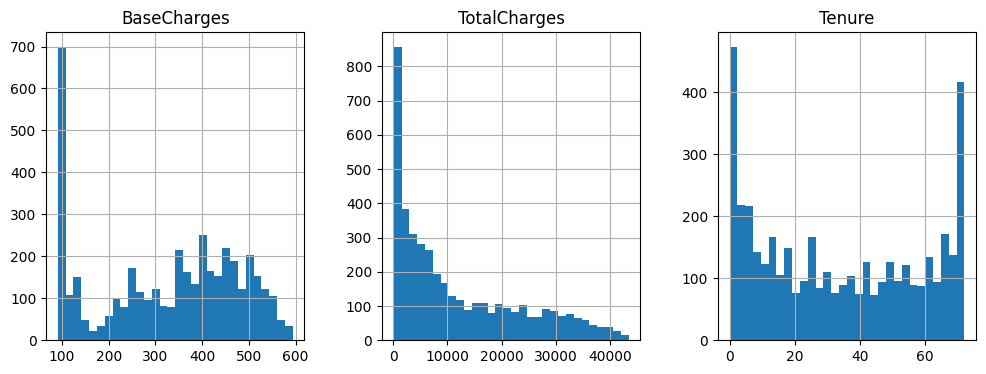

In [98]:
# histograms for the numerical variables
df[['BaseCharges', 'TotalCharges', 'Tenure']].hist(figsize=(12, 4), bins=30, layout=(1, 3))
plt.show()

- `BaseCharges` has a big group of customers with low charges and the rest spread between about 200 and 550.
- `TotalCharges` is skewed to the right.
- `Tenure` has two peaks: many new customers and many customers who have stayed for about 6 years.

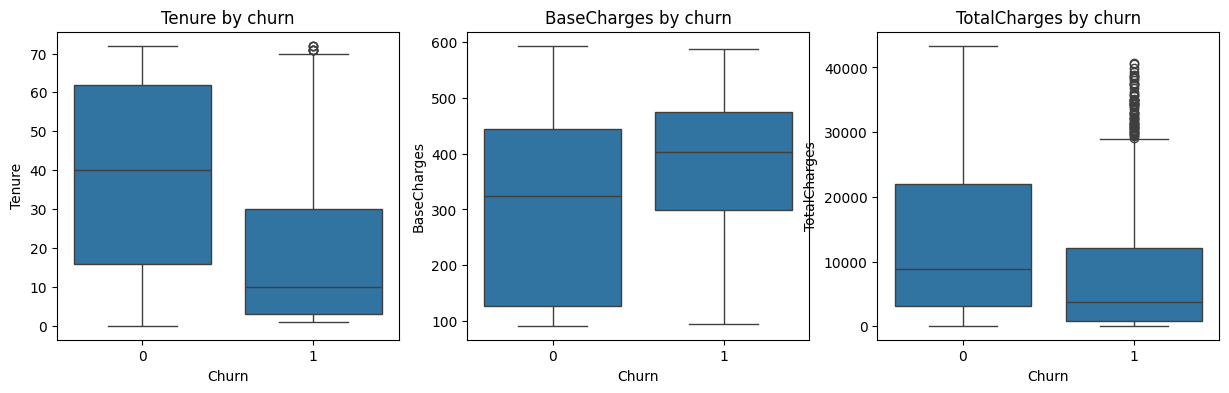

In [99]:
# how do the numerical variables differ between customers who churned and who did not?
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
for ax, col in zip(axes, ['Tenure', 'BaseCharges', 'TotalCharges']):
    sns.boxplot(data=df, x='Churn', y=col, ax=ax)
    ax.set_title(f'{col} by churn')
plt.show()

Customers who churned have a much shorter tenure and higher base charges. Their total charges are lower, which makes sense because they did not stay long.

In [100]:
# churn rate by contract type
df.groupby('ContractType')['Churn'].value_counts(normalize=True)

ContractType    Churn
Month-to-month  0        0.589709
                1        0.410291
One year        0        0.890098
                1        0.109902
Two year        0        0.972248
                1        0.027752
Name: proportion, dtype: float64

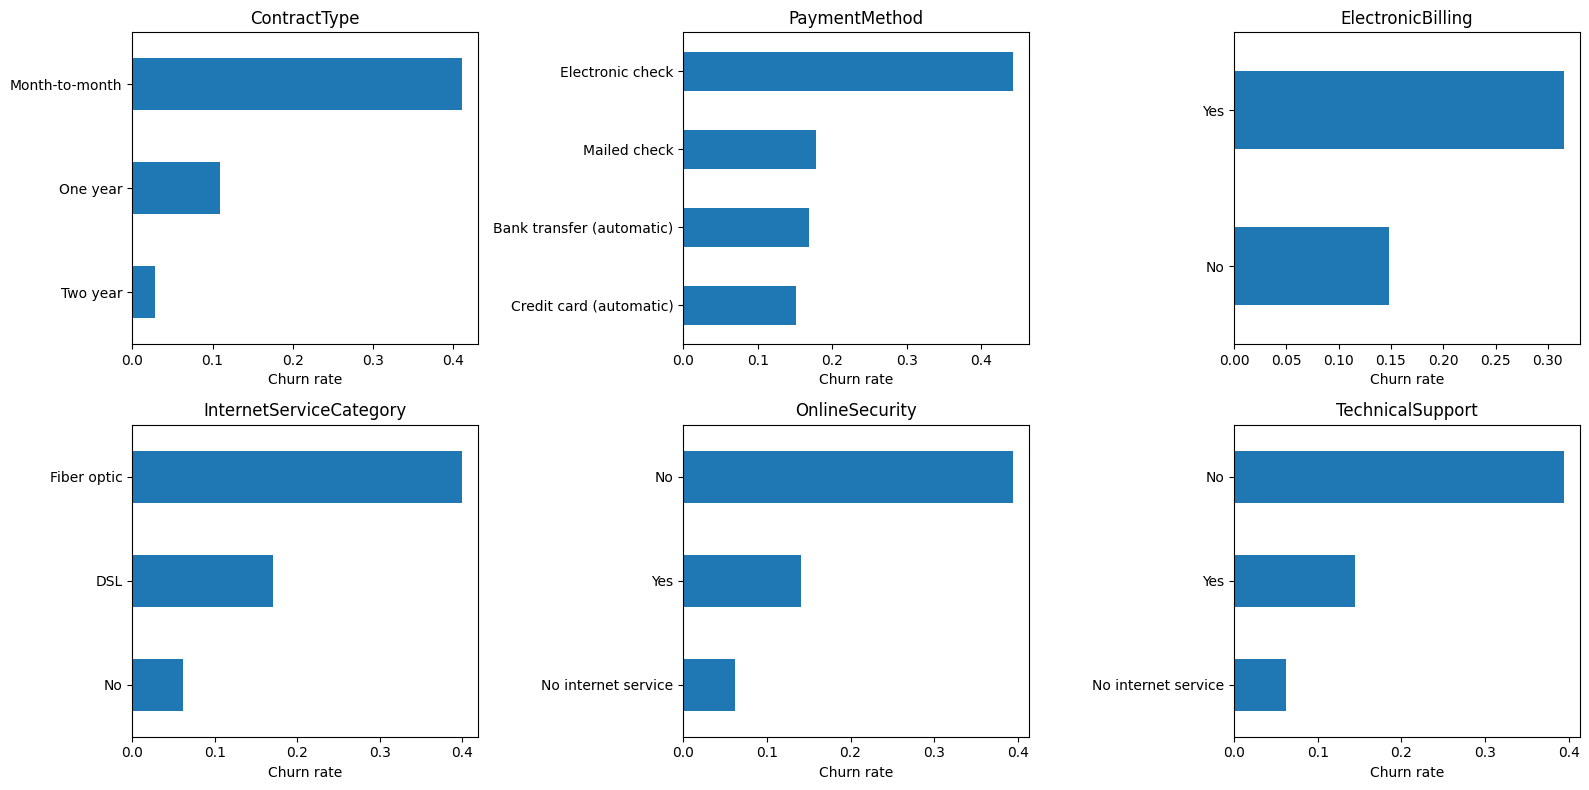

In [101]:
# churn rate for the categorical variables related to the account and the internet service
fig, axes = plt.subplots(2, 3, figsize=(16, 8))
cols = ['ContractType', 'PaymentMethod', 'ElectronicBilling', 'InternetServiceCategory', 'OnlineSecurity', 'TechnicalSupport']
for ax, col in zip(axes.flatten(), cols):
    rate = df.groupby(col)['Churn'].mean().sort_values()
    rate.plot(kind='barh', ax=ax)
    ax.set_xlabel('Churn rate')
    ax.set_ylabel('')
    ax.set_title(col)
plt.tight_layout()
plt.show()

- **ContractType**: month-to-month customers churn far more than customers on one-year or two-year contracts.
- **PaymentMethod**: customers paying by electronic check churn the most.
- **InternetServiceCategory**: fiber optic customers churn more than DSL customers; customers with no internet service rarely churn.
- **OnlineSecurity / TechnicalSupport**: customers without these services churn more.

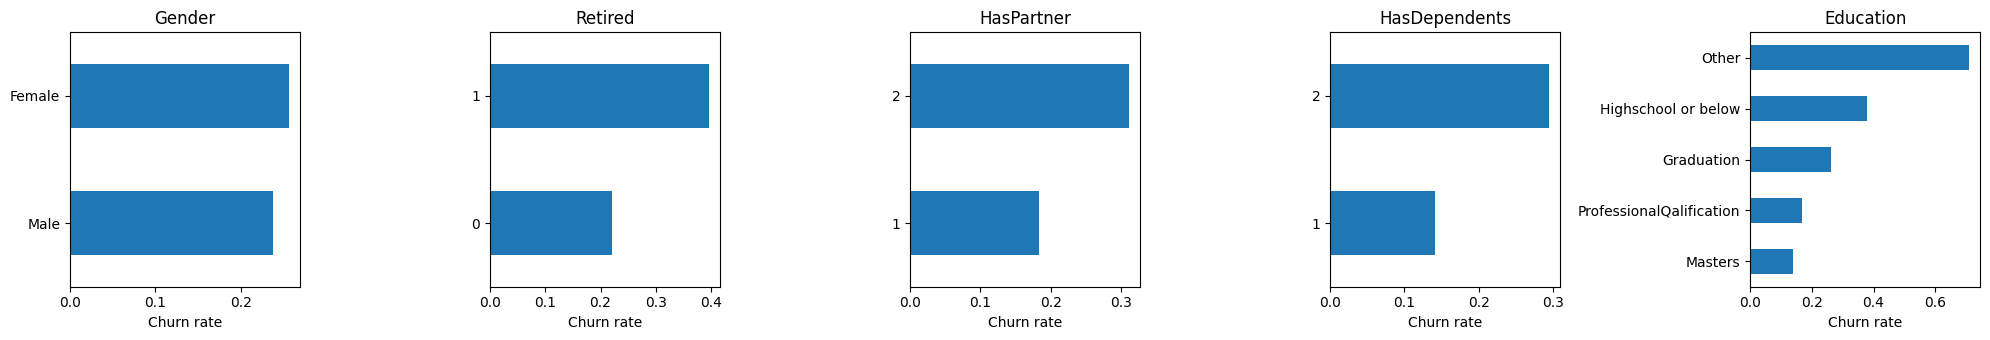

In [102]:
# churn rate for the demographic variables
fig, axes = plt.subplots(1, 5, figsize=(20, 3.5))
for ax, col in zip(axes, ['Gender', 'Retired', 'HasPartner', 'HasDependents', 'Education']):
    rate = df.groupby(col)['Churn'].mean().sort_values()
    rate.plot(kind='barh', ax=ax)
    ax.set_xlabel('Churn rate')
    ax.set_ylabel('')
    ax.set_title(col)
plt.tight_layout()
plt.show()

Gender makes almost no difference. Retired customers churn more, and so do customers with HasPartner = 2 and HasDependents = 2 (the data description does not say what 1 and 2 mean). Churn also differs by education: it is highest for 'Other' (a very small group) and 'Highschool or below' and lowest for 'Masters'.

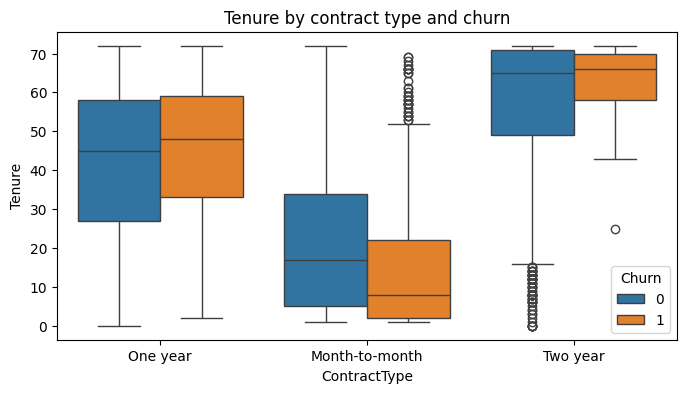

In [103]:
# Tenure and contract type together
fig, ax = plt.subplots(figsize=(8, 4))
sns.boxplot(data=df, x='ContractType', y='Tenure', hue='Churn', ax=ax)
ax.set_title('Tenure by contract type and churn')
plt.show()

## 5. Preprocessing

Selection:
- Target: `Churn`
- Numerical variables: `BaseCharges`, `TotalCharges`, `Tenure`, `Retired`, `HasPartner`, `HasDependents`
- Categorical variables: the account variables, `Education`, `Gender`, and the nine service variables

Handling missing values:
- numerical variables: fill with the median
- categorical variables: fill with the most frequent value

Standardization: scale the numerical variables to lie between 0 and 1 using `MinMaxScaler`.

Encoding: I try both `OrdinalEncoder` and `OneHotEncoder` for the categorical variables.

I use a pipeline so that the imputer, scaler, and encoder are fitted once on the training set and reused for the test set.

In [104]:
# Prepare the training inputs and target
X = df.drop('Churn', axis=1)
y = df['Churn']
print(X.shape)
print(y.shape)

(4238, 20)
(4238,)


In [105]:
# Define the numerical and categorical columns once
# NOTE: Retired, HasPartner, and HasDependents only have two values each, so I keep them as numerical attributes
num_cols = ['BaseCharges', 'TotalCharges', 'Tenure', 'Retired', 'HasPartner', 'HasDependents']
cat_cols = ['ElectronicBilling', 'ContractType', 'PaymentMethod', 'Education', 'Gender',
            'DeviceProtection', 'HasPhoneService', 'InternetServiceCategory', 'MultipleLines',
            'OnlineBackup', 'OnlineSecurity', 'StreamingMovies', 'StreamingTelevision', 'TechnicalSupport']
print(len(num_cols), len(cat_cols))

6 14


In [106]:
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import MinMaxScaler, OrdinalEncoder, OneHotEncoder

# Numerical columns: fill missing values, then scale
num_pipeline = Pipeline([
    ('imputer', SimpleImputer(strategy='median')),
    ('scaler', MinMaxScaler())
])

# Categorical columns: fill missing values, then use ordinal encoding
cat_pipeline_ordinal = Pipeline([
    ('imputer', SimpleImputer(strategy='most_frequent')),
    ('encoder', OrdinalEncoder(handle_unknown='use_encoded_value', unknown_value=-1))  # encode unseen test categories as -1
])

# Categorical columns: fill missing values, then use one-hot encoding
cat_pipeline_onehot = Pipeline([
    ('imputer', SimpleImputer(strategy='most_frequent')),
    ('encoder', OneHotEncoder(handle_unknown='ignore'))  # ignore unseen test categories
])

preprocess_ordinal = ColumnTransformer([
    ('num', num_pipeline, num_cols),
    ('cat', cat_pipeline_ordinal, cat_cols)
])

preprocess_onehot = ColumnTransformer([
    ('num', num_pipeline, num_cols),
    ('cat', cat_pipeline_onehot, cat_cols)
])

In [107]:
# take a look at the training set after preprocessing with one-hot encoding
X_onehot = preprocess_onehot.fit_transform(X)
X_onehot = pd.DataFrame(X_onehot, columns=preprocess_onehot.get_feature_names_out())
print(X_onehot.shape)
X_onehot.head()

(4238, 48)


,num__BaseCharges,num__TotalCharges,num__Tenure,num__Retired,num__HasPartner,num__HasDependents,cat__ElectronicBilling_No,cat__ElectronicBilling_Yes,cat__ContractType_Month-to-month,cat__ContractType_One year,...,cat__OnlineSecurity_Yes,cat__StreamingMovies_No,cat__StreamingMovies_No internet service,cat__StreamingMovies_Yes,cat__StreamingTelevision_No,cat__StreamingTelevision_No internet service,cat__StreamingTelevision_Yes,cat__TechnicalSupport_No,cat__TechnicalSupport_No internet service,cat__TechnicalSupport_Yes
0,0.770647,0.134643,0.166667,0.0,1.0,1.0,1.0,0.0,0.0,1.0,...,0.0,0.0,0.0,1.0,0.0,0.0,1.0,1.0,0.0,0.0
1,0.023881,0.000208,0.013889,0.0,1.0,1.0,1.0,0.0,1.0,0.0,...,0.0,0.0,1.0,0.0,0.0,1.0,0.0,0.0,1.0,0.0
2,0.559701,0.006431,0.013889,0.0,1.0,1.0,0.0,1.0,1.0,0.0,...,0.0,1.0,0.0,0.0,1.0,0.0,0.0,1.0,0.0,0.0
3,0.016418,0.154416,0.986111,0.0,1.0,1.0,0.0,1.0,0.0,0.0,...,0.0,0.0,1.0,0.0,0.0,1.0,0.0,0.0,1.0,0.0
4,0.000000,0.059611,0.388889,0.0,1.0,1.0,1.0,0.0,0.0,1.0,...,0.0,0.0,1.0,0.0,0.0,1.0,0.0,0.0,1.0,0.0


## 6. Building the Models

I build four models:
1. Decision tree with ordinal encoding
2. Decision tree with one-hot encoding
3. Logistic regression with one-hot encoding
4. Random forest with one-hot encoding

Kaggle only allows a limited number of submissions, so I use 5-fold cross validation on the training set to estimate the accuracy of each model before submitting.

In [108]:
from sklearn.tree import DecisionTreeClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import cross_val_score

# save the cross validation accuracy of each model for comparison
results = {}

### Model 1: Decision tree with ordinal encoding

In [109]:
tree_ordinal_pipeline = Pipeline([
    ('preprocess', preprocess_ordinal),
    ('model', DecisionTreeClassifier(criterion='entropy', max_depth=3))
])

# Fit the full pipeline once on the training set
tree_ordinal_pipeline.fit(X, y)

Pipeline(steps=[('preprocess',
                 ColumnTransformer(transformers=[('num',
                                                  Pipeline(steps=[('imputer',
                                                                   SimpleImputer(strategy='median')),
                                                                  ('scaler',
                                                                   MinMaxScaler())]),
                                                  ['BaseCharges',
                                                   'TotalCharges', 'Tenure',
                                                   'Retired', 'HasPartner',
                                                   'HasDependents']),
                                                 ('cat',
                                                  Pipeline(steps=[('imputer',
                                                                   SimpleImputer(strategy='most_frequent')),
                                                                  ('encoder',
                                                                   OrdinalEncoder(handle_unkn...ncoded_value',
                                                                                  unknown_value=-1))]),
                                                  ['ElectronicBilling',
                                                   'ContractType',
                                                   'PaymentMethod', 'Education',
                                                   'Gender', 'DeviceProtection',
                                                   'HasPhoneService',
                                                   'InternetServiceCategory',
                                                   'MultipleLines',
                                                   'OnlineBackup',
                                                   'OnlineSecurity',
                                                   'StreamingMovies',
                                                   'StreamingTelevision',
                                                   'TechnicalSupport'])])),
                ('model',
                 DecisionTreeClassifier(criterion='entropy', max_depth=3))])

In [110]:
scores = cross_val_score(tree_ordinal_pipeline, X, y, cv=5, scoring='accuracy')
results['Decision tree (ordinal)'] = scores.mean()
print(scores)
print(f'cross validation accuracy: {scores.mean():.4f}')

[0.78773585 0.78301887 0.7865566  0.79456907 0.79929162]
cross validation accuracy: 0.7902


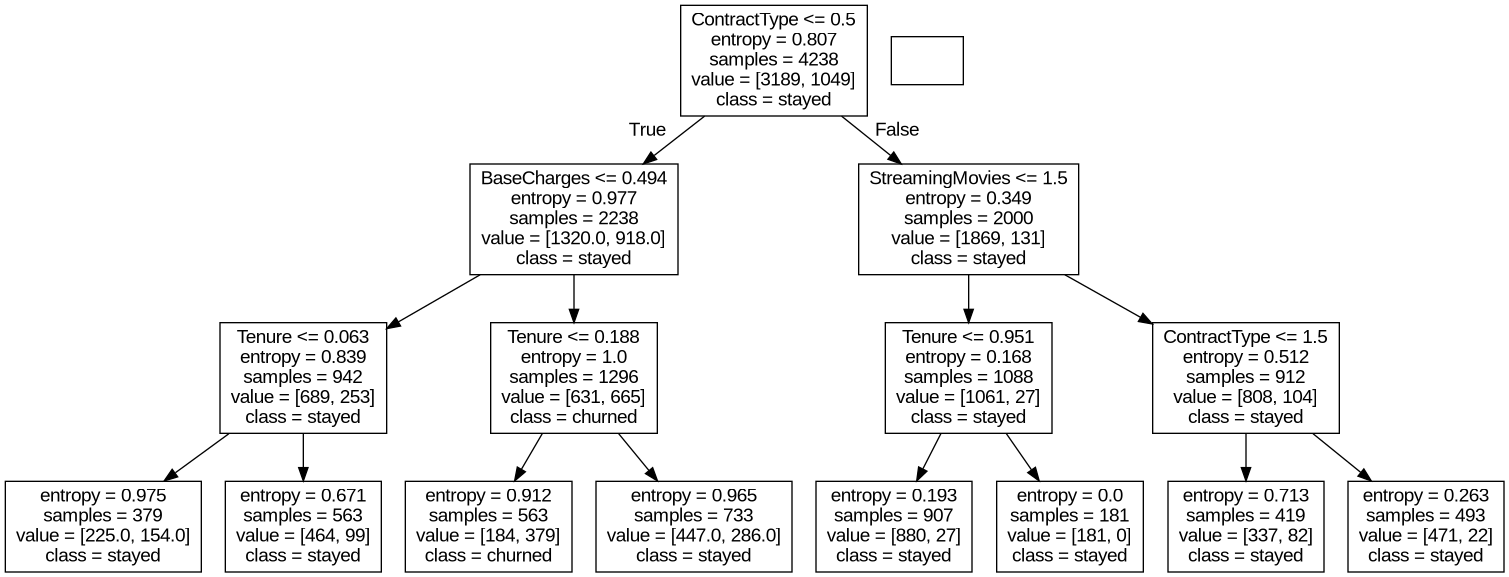

In [111]:
# For visualizing the tree
from IPython.display import Image
from sklearn import tree
import pydotplus

cls_names = ['stayed', 'churned']

# Create DOT data
dot_data = tree.export_graphviz(tree_ordinal_pipeline.named_steps['model'],
                                feature_names=num_cols + cat_cols,
                                class_names=cls_names,
                               )

# Draw graph
graph = pydotplus.graph_from_dot_data(dot_data)

# Show graph
Image(graph.create_png())

The tree splits on `ContractType` first, then on `BaseCharges` and `StreamingMovies`, and then on `Tenure`. Contract type and tenure also stood out in the EDA.

### Model 2: Decision tree with one-hot encoding

Most categorical variables here (e.g., PaymentMethod, InternetServiceCategory) have no natural order, so one-hot encoding is more appropriate than ordinal encoding. I also try different values of max_depth.

In [112]:
# try different max_depth
for depth in [2, 3, 4, 5, 6, 8, 10]:
    pipeline = Pipeline([
        ('preprocess', preprocess_onehot),
        ('model', DecisionTreeClassifier(criterion='entropy', max_depth=depth, random_state=42))
    ])
    scores = cross_val_score(pipeline, X, y, cv=5, scoring='accuracy')
    print(f'max_depth={depth}: {scores.mean():.4f}')

max_depth=2: 0.7735
max_depth=3: 0.8004
max_depth=4: 0.8032
max_depth=5: 0.8046
max_depth=6: 0.8001
max_depth=8: 0.7865
max_depth=10: 0.7728


A deeper tree does not keep improving the accuracy. A very deep tree starts to overfit. I choose max_depth=5.

In [113]:
tree_onehot_pipeline = Pipeline([
    ('preprocess', preprocess_onehot),
    ('model', DecisionTreeClassifier(criterion='entropy', max_depth=5, random_state=42))
])
tree_onehot_pipeline.fit(X, y)

Pipeline(steps=[('preprocess',
                 ColumnTransformer(transformers=[('num',
                                                  Pipeline(steps=[('imputer',
                                                                   SimpleImputer(strategy='median')),
                                                                  ('scaler',
                                                                   MinMaxScaler())]),
                                                  ['BaseCharges',
                                                   'TotalCharges', 'Tenure',
                                                   'Retired', 'HasPartner',
                                                   'HasDependents']),
                                                 ('cat',
                                                  Pipeline(steps=[('imputer',
                                                                   SimpleImputer(strategy='most_frequent')),
                                                                  ('encoder',
                                                                   OneHotEncoder(handle_unknown='ignore'))]),
                                                  ['ElectronicBilling',
                                                   'ContractType',
                                                   'PaymentMethod', 'Education',
                                                   'Gender', 'DeviceProtection',
                                                   'HasPhoneService',
                                                   'InternetServiceCategory',
                                                   'MultipleLines',
                                                   'OnlineBackup',
                                                   'OnlineSecurity',
                                                   'StreamingMovies',
                                                   'StreamingTelevision',
                                                   'TechnicalSupport'])])),
                ('model',
                 DecisionTreeClassifier(criterion='entropy', max_depth=5,
                                        random_state=42))])

In [114]:
scores = cross_val_score(tree_onehot_pipeline, X, y, cv=5, scoring='accuracy')
results['Decision tree (one-hot)'] = scores.mean()
print(scores)
print(f'cross validation accuracy: {scores.mean():.4f}')

[0.8125     0.79834906 0.80542453 0.7957497  0.81109799]
cross validation accuracy: 0.8046


### Model 3: Logistic regression with one-hot encoding

Logistic regression is the classification version of the linear regression model. It estimates the probability of churn and predicts Churn = 1 if the probability is above 50%.

https://scikit-learn.org/stable/modules/generated/sklearn.linear_model.LogisticRegression.html

In [115]:
logit_pipeline = Pipeline([
    ('preprocess', preprocess_onehot),
    ('model', LogisticRegression(max_iter=1000))
])
logit_pipeline.fit(X, y)

Pipeline(steps=[('preprocess',
                 ColumnTransformer(transformers=[('num',
                                                  Pipeline(steps=[('imputer',
                                                                   SimpleImputer(strategy='median')),
                                                                  ('scaler',
                                                                   MinMaxScaler())]),
                                                  ['BaseCharges',
                                                   'TotalCharges', 'Tenure',
                                                   'Retired', 'HasPartner',
                                                   'HasDependents']),
                                                 ('cat',
                                                  Pipeline(steps=[('imputer',
                                                                   SimpleImputer(strategy='most_frequent')),
                                                                  ('encoder',
                                                                   OneHotEncoder(handle_unknown='ignore'))]),
                                                  ['ElectronicBilling',
                                                   'ContractType',
                                                   'PaymentMethod', 'Education',
                                                   'Gender', 'DeviceProtection',
                                                   'HasPhoneService',
                                                   'InternetServiceCategory',
                                                   'MultipleLines',
                                                   'OnlineBackup',
                                                   'OnlineSecurity',
                                                   'StreamingMovies',
                                                   'StreamingTelevision',
                                                   'TechnicalSupport'])])),
                ('model', LogisticRegression(max_iter=1000))])

In [116]:
scores = cross_val_score(logit_pipeline, X, y, cv=5, scoring='accuracy')
results['Logistic regression'] = scores.mean()
print(scores)
print(f'cross validation accuracy: {scores.mean():.4f}')

[0.83136792 0.83018868 0.80778302 0.81936246 0.82880756]
cross validation accuracy: 0.8235


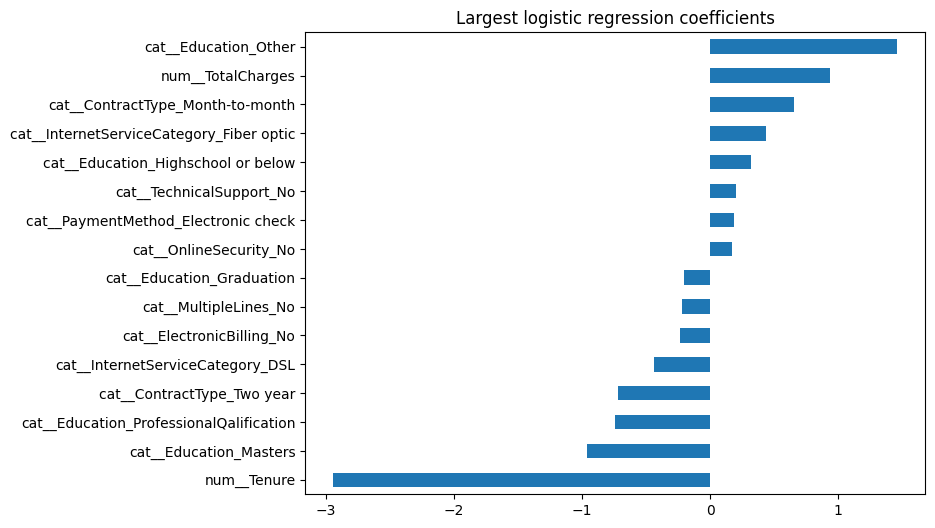

In [117]:
# the coefficients: positive means higher chance of churn, negative means lower chance of churn
coef = pd.Series(logit_pipeline.named_steps['model'].coef_[0],
                 index=logit_pipeline.named_steps['preprocess'].get_feature_names_out())
coef = coef.sort_values()
pd.concat([coef.head(8), coef.tail(8)]).plot(kind='barh', figsize=(8, 6))
plt.title('Largest logistic regression coefficients')
plt.show()

### Model 4: Random forest with one-hot encoding

A random forest builds many decision trees on random samples of the data and lets them vote. It usually overfits less than a single tree.

https://scikit-learn.org/stable/modules/generated/sklearn.ensemble.RandomForestClassifier.html

In [118]:
forest_pipeline = Pipeline([
    ('preprocess', preprocess_onehot),
    ('model', RandomForestClassifier(n_estimators=200, max_depth=8, random_state=42))
])
forest_pipeline.fit(X, y)

Pipeline(steps=[('preprocess',
                 ColumnTransformer(transformers=[('num',
                                                  Pipeline(steps=[('imputer',
                                                                   SimpleImputer(strategy='median')),
                                                                  ('scaler',
                                                                   MinMaxScaler())]),
                                                  ['BaseCharges',
                                                   'TotalCharges', 'Tenure',
                                                   'Retired', 'HasPartner',
                                                   'HasDependents']),
                                                 ('cat',
                                                  Pipeline(steps=[('imputer',
                                                                   SimpleImputer(strategy='most_frequent')),
                                                                  ('encoder',
                                                                   OneHotEncoder(handle_unknown='ignore'))]),
                                                  ['ElectronicBilling',
                                                   'ContractType',
                                                   'PaymentMethod', 'Education',
                                                   'Gender', 'DeviceProtection',
                                                   'HasPhoneService',
                                                   'InternetServiceCategory',
                                                   'MultipleLines',
                                                   'OnlineBackup',
                                                   'OnlineSecurity',
                                                   'StreamingMovies',
                                                   'StreamingTelevision',
                                                   'TechnicalSupport'])])),
                ('model',
                 RandomForestClassifier(max_depth=8, n_estimators=200,
                                        random_state=42))])

In [119]:
scores = cross_val_score(forest_pipeline, X, y, cv=5, scoring='accuracy')
results['Random forest'] = scores.mean()
print(scores)
print(f'cross validation accuracy: {scores.mean():.4f}')

[0.83136792 0.81485849 0.81485849 0.81227863 0.81818182]
cross validation accuracy: 0.8183


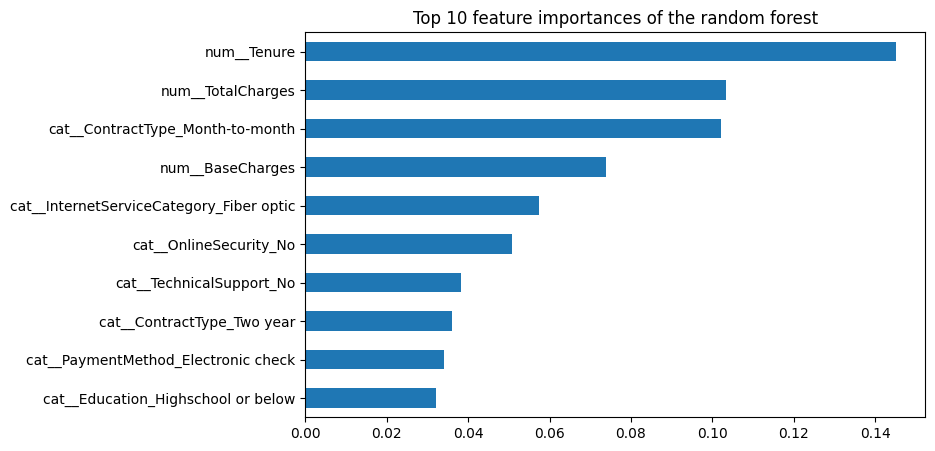

In [120]:
# which variables are the most important in the random forest?
importance = pd.Series(forest_pipeline.named_steps['model'].feature_importances_,
                       index=forest_pipeline.named_steps['preprocess'].get_feature_names_out())
importance.sort_values().tail(10).plot(kind='barh', figsize=(8, 5))
plt.title('Top 10 feature importances of the random forest')
plt.show()

### Compare the models

In [121]:
df_results = pd.DataFrame({'cv_accuracy': results}).sort_values('cv_accuracy', ascending=False)
df_results

,cv_accuracy
Logistic regression,0.823502
Random forest,0.818309
Decision tree (one-hot),0.804624
Decision tree (ordinal),0.790234


All four models are above the naive all-zero model on the training set (75.2%) and above the Kaggle baseline (0.71698). Logistic regression has the highest cross validation accuracy, followed by the random forest.

## 7. Making Predictions for Submission on Kaggle

When we make predictions, the input dataframe must match the structure of the training dataframe. The pipelines apply the same imputer, scaler, and encoder learned from the training data.

In [122]:
# the column array for the testing input dataframe
df_test.columns.values

array(['BaseCharges', 'TotalCharges', 'ElectronicBilling', 'ContractType',
       'PaymentMethod', 'Retired', 'HasPartner', 'HasDependents',
       'Education', 'Gender', 'DeviceProtection', 'HasPhoneService',
       'InternetServiceCategory', 'MultipleLines', 'OnlineBackup',
       'OnlineSecurity', 'StreamingMovies', 'StreamingTelevision',
       'TechnicalSupport', 'Tenure'], dtype=object)

In [123]:
# the column array for the training input dataframe
X.columns.values

array(['BaseCharges', 'TotalCharges', 'ElectronicBilling', 'ContractType',
       'PaymentMethod', 'Retired', 'HasPartner', 'HasDependents',
       'Education', 'Gender', 'DeviceProtection', 'HasPhoneService',
       'InternetServiceCategory', 'MultipleLines', 'OnlineBackup',
       'OnlineSecurity', 'StreamingMovies', 'StreamingTelevision',
       'TechnicalSupport', 'Tenure'], dtype=object)

In [124]:
# make predictions with each model and save the csv files for Kaggle submission
models = {
    'churn_submit_tree_ordinal.csv': tree_ordinal_pipeline,
    'churn_submit_tree_onehot.csv': tree_onehot_pipeline,
    'churn_submit_logit.csv': logit_pipeline,
    'churn_submit_forest.csv': forest_pipeline,
}

for filename, model in models.items():
    # convert predictions to integer
    y_hat = model.predict(df_test).astype(int)
    df_submit = pd.DataFrame({
        'CustomerNo': df_test_id,
        'Churn': y_hat,
    })
    df_submit.to_csv(f'{output_dir}{filename}', index=False)
    print(f'{filename}: {df_submit.shape[0]} rows, predicted churn rate {y_hat.mean():.1%}')

churn_submit_tree_ordinal.csv: 1060 rows, predicted churn rate 12.7%
churn_submit_tree_onehot.csv: 1060 rows, predicted churn rate 17.6%
churn_submit_logit.csv: 1060 rows, predicted churn rate 19.5%
churn_submit_forest.csv: 1060 rows, predicted churn rate 16.5%


In [125]:
# check the format against the sample submission
df_submit = pd.read_csv(f'{output_dir}churn_submit_logit.csv')
print(df_submit.columns.tolist() == df_sample.columns.tolist())
print((df_submit['CustomerNo'] == df_sample['CustomerNo']).all())
df_submit.head()

True
True


,CustomerNo,Churn
0,1203,0
1,1204,0
2,1208,0
3,1220,0
4,1221,0


Submit these files to Kaggle. Check the scores and ranking.